# Credit Card Case Study – Exploratory Data Analysis

**Objective:** Analyze customer acquisition, credit-card spend, and repayment behavior for PSPD Bank using Python, Pandas and visualization.

This notebook follows the questions and requirements given in the supplied AnalytixLabs case study.

### Data files
- `Customer Acqusition.csv` – customer/card details
- `spend.csv` – transaction/spend data
- `Repayment.csv` – repayment data

The case study asks us to clean values against the customer's transaction limit, create business summaries, visualize trends, and build a reusable user-defined function for the top 10 repayment customers by city/product/time period.


## 1. Import libraries and load data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

DATA_DIR = Path('.')

customer = pd.read_csv(DATA_DIR / 'Customer Acqusition.csv')
spend = pd.read_csv(DATA_DIR / 'spend.csv')
repayment = pd.read_csv(DATA_DIR / 'Repayment.csv')

print('Customer Acquisition:', customer.shape)
print('Spend:', spend.shape)
print('Repayment:', repayment.shape)

display(customer.head())
display(spend.head())
display(repayment.head())


Customer Acquisition: (100, 8)
Spend: (1500, 5)
Repayment: (1500, 4)


,No,Customer,Age,City,Product,Limit,Company,Segment
0,1,A1,76,BANGALORE,Gold,"500,000.00",C1,Self Employed
1,2,A2,71,CALCUTTA,Silver,"100,000.00",C2,Salaried_MNC
2,3,A3,34,COCHIN,Platimum,"10,000.00",C3,Salaried_Pvt
3,4,A4,47,BOMBAY,Platimum,"10,001.00",C4,Govt
4,5,A5,56,BANGALORE,Platimum,"10,002.00",C5,Normal Salary


,Sl No:,Customer,Month,Type,Amount
0,1,A1,12-Jan-04,JEWELLERY,"485,470.80"
1,2,A1,3-Jan-04,PETRO,"410,556.13"
2,3,A1,15-Jan-04,CLOTHES,"23,740.46"
3,4,A1,25-Jan-04,FOOD,"484,342.47"
4,5,A1,17-Jan-05,CAMERA,"369,694.07"


,SL No:,Customer,Month,Amount
0,NaN,A1,12-Jan-04,"495,414.75"
1,2.00,A1,03-Jan-04,"245,899.02"
2,3.00,A1,15-Jan-04,"259,490.06"
3,4.00,A1,25-Jan-04,"437,555.12"
4,5.00,A1,17-Jan-05,"165,972.88"


## 2. Initial data inspection

In [2]:
print('Customer information')
customer.info()

print('\nSpend information')
spend.info()

print('\nRepayment information')
repayment.info()

print('\nMissing values')
display(pd.DataFrame({
    'Customer Acquisition': customer.isna().sum(),
    'Spend': spend.isna().sum(),
    'Repayment': repayment.isna().sum()
}).fillna(0))


Customer information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 8 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   No        100 non-null    int64  
 1   Customer  100 non-null    object 
 2   Age       100 non-null    int64  
 3   City      100 non-null    object 
 4   Product   100 non-null    object 
 5   Limit     100 non-null    float64
 6   Company   100 non-null    object 
 7   Segment   100 non-null    object 
dtypes: float64(1), int64(2), object(5)
memory usage: 6.4+ KB

Spend information
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Sl No:    1500 non-null   int64  
 1   Customer  1500 non-null   object 
 2   Month     1500 non-null   object 
 3   Type      1500 non-null   object 
 4   Amount    1500 non-null   float64
dtypes: float64(1), int64(

,Customer Acquisition,Spend,Repayment
Age,0.00,0.00,0.00
Amount,0.00,0.00,0.00
City,0.00,0.00,0.00
Company,0.00,0.00,0.00
Customer,0.00,0.00,0.00
Limit,0.00,0.00,0.00
Month,0.00,0.00,0.00
No,0.00,0.00,0.00
Product,0.00,0.00,0.00
SL No:,0.00,0.00,1.00


## 3. Data cleaning

The case study specifies three important corrections:

1. If age is below 18, replace it with the mean age.
2. If spend is greater than the customer's card limit, replace it with 50% of that customer's limit.
3. If repayment is greater than the customer's card limit, replace it with the customer's limit.

The customer limit is a **per-transaction limit**. We therefore merge the customer limit into both transaction datasets before applying the rules. fileciteturn0file0L51-L63


In [3]:
# Work on copies so the raw data remains unchanged
customer_clean = customer.copy()
spend_clean = spend.copy()
repayment_clean = repayment.copy()

# Standardize numeric types
customer_clean['Age'] = customer_clean['Age'].astype(float)

# Case study rule 1: age below 18 -> mean age
mean_age = customer_clean.loc[customer_clean['Age'] >= 18, 'Age'].mean()
age_replaced_count = (customer_clean['Age'] < 18).sum()
customer_clean.loc[customer_clean['Age'] < 18, 'Age'] = mean_age

# Parse transaction dates
spend_clean['Month'] = pd.to_datetime(spend_clean['Month'], format='%d-%b-%y')
repayment_clean['Month'] = pd.to_datetime(repayment_clean['Month'], format='%d-%b-%y')

# Merge card limit into transactions
spend_clean = spend_clean.merge(
    customer_clean[['Customer', 'Limit']],
    on='Customer',
    how='left'
)

repayment_clean = repayment_clean.merge(
    customer_clean[['Customer', 'Limit']],
    on='Customer',
    how='left'
)

# Case study rule 2: spend above limit -> 50% of limit
spend_over_limit = spend_clean['Amount'] > spend_clean['Limit']
spend_over_limit_count = spend_over_limit.sum()
spend_clean['Amount_Clean'] = np.where(
    spend_over_limit,
    spend_clean['Limit'] * 0.50,
    spend_clean['Amount']
)

# Case study rule 3: repayment above limit -> limit
repayment_over_limit = repayment_clean['Amount'] > repayment_clean['Limit']
repayment_over_limit_count = repayment_over_limit.sum()
repayment_clean['Amount_Clean'] = np.where(
    repayment_over_limit,
    repayment_clean['Limit'],
    repayment_clean['Amount']
)

# The source data contains the spelling 'Platimum'. Standardize it for analysis.
customer_clean['Product'] = customer_clean['Product'].replace({'Platimum': 'Platinum'})

print(f'Age values replaced (<18): {age_replaced_count}')
print(f'Spend transactions above limit: {spend_over_limit_count}')
print(f'Repayment transactions above limit: {repayment_over_limit_count}')
print(f'Mean age used for replacement: {mean_age:.2f}')
print('\nProduct labels after standardization:')
print(customer_clean['Product'].value_counts())


Age values replaced (<18): 6
Spend transactions above limit: 607
Repayment transactions above limit: 600
Mean age used for replacement: 48.52

Product labels after standardization:
Product
Gold        38
Platinum    32
Silver      30
Name: count, dtype: int64


## 4. Basic customer and category summaries

The case study asks for the number of distinct customers and distinct transaction categories. fileciteturn0file0L64-L69

In [4]:
distinct_customers = customer_clean['Customer'].nunique()
distinct_categories = spend_clean['Type'].nunique()

print('Distinct customers:', distinct_customers)
print('Distinct transaction categories:', distinct_categories)


Distinct customers: 100
Distinct transaction categories: 15


## 5. Average monthly spend and repayment

For a customer-level monthly measure, first aggregate each customer's transactions by month and then take the average of those customer-month totals.

In [5]:
spend_clean['Period'] = spend_clean['Month'].dt.to_period('M')
repayment_clean['Period'] = repayment_clean['Month'].dt.to_period('M')

customer_monthly_spend = (
    spend_clean.groupby(['Customer', 'Period'])['Amount_Clean']
    .sum()
    .reset_index()
)

customer_monthly_repayment = (
    repayment_clean.groupby(['Customer', 'Period'])['Amount_Clean']
    .sum()
    .reset_index()
)

avg_monthly_spend = customer_monthly_spend['Amount_Clean'].mean()
avg_monthly_repayment = customer_monthly_repayment['Amount_Clean'].mean()

print(f'Average monthly spend by customer: ₹{avg_monthly_spend:,.2f}')
print(f'Average monthly repayment by customer: ₹{avg_monthly_repayment:,.2f}')


Average monthly spend by customer: ₹272,343.35
Average monthly repayment by customer: ₹306,995.44


## 6. Monthly bank profit at 2.9% interest

According to the case study:

**Monthly Profit = Monthly Repayment − Monthly Spend**

Interest is earned only when Monthly Profit is positive:

**Bank Interest = max(Monthly Profit, 0) × 2.9%** fileciteturn0file0L69-L71

In [6]:
monthly_financials = (
    spend_clean.groupby('Period')['Amount_Clean'].sum().rename('Monthly Spend')
    .to_frame()
    .join(
        repayment_clean.groupby('Period')['Amount_Clean'].sum().rename('Monthly Repayment'),
        how='outer'
    )
    .fillna(0)
)

monthly_financials['Monthly Profit'] = (
    monthly_financials['Monthly Repayment'] - monthly_financials['Monthly Spend']
)

interest_rate = 0.029

monthly_financials['Bank Interest'] = (
    monthly_financials['Monthly Profit'].clip(lower=0) * interest_rate
)

display(monthly_financials)

print(f'Total bank interest across all months: ₹{monthly_financials["Bank Interest"].sum():,.2f}')


,Monthly Spend,Monthly Repayment,Monthly Profit,Bank Interest
Period,,,,
2004-01,"44,279,811.96","44,792,020.72","512,208.76","14,854.05"
2004-02,"3,835,951.84","3,391,537.65","-444,414.19",0.00
2004-03,"1,871,913.27","2,666,519.22","794,605.95","23,043.57"
2004-04,"3,489,415.34","5,268,979.74","1,779,564.40","51,607.37"
2004-05,"2,146,577.36","3,782,759.91","1,636,182.55","47,449.29"
2004-09,"2,402,109.69","1,902,816.41","-499,293.28",0.00
2004-11,"1,114,989.10","1,788,398.63","673,409.53","19,528.88"
2005-01,"5,383,606.78","4,894,040.25","-489,566.53",0.00
2005-02,"25,928,183.21","25,491,800.20","-436,383.01",0.00


Total bank interest across all months: ₹998,733.65


## 7. Top 5 product types

The case study asks for the top five product/transaction types based on spend. fileciteturn0file0L74-L77

In [7]:
top_5_products = (
    spend_clean.groupby('Type')['Amount_Clean']
    .sum()
    .sort_values(ascending=False)
    .head(5)
    .reset_index()
)

display(top_5_products)


,Type,Amount_Clean
0,PETRO,"28,597,384.98"
1,CAMERA,"27,690,738.44"
2,FOOD,"20,519,243.60"
3,AIR TICKET,"20,155,847.12"
4,TRAIN TICKET,"19,995,825.72"


## 8. City with maximum spend

In [8]:
spend_with_customer = spend_clean.merge(
    customer_clean[['Customer', 'City', 'Product', 'Age']],
    on='Customer',
    how='left'
)

city_spend = (
    spend_with_customer.groupby('City')['Amount_Clean']
    .sum()
    .sort_values(ascending=False)
)

display(city_spend.to_frame('Total Spend'))

print('City with maximum spend:', city_spend.idxmax())
print(f'Maximum spend: ₹{city_spend.max():,.2f}')


,Total Spend
City,
COCHIN,"45,963,513.50"
CALCUTTA,"41,108,132.30"
BANGALORE,"40,461,647.02"
BOMBAY,"28,603,127.38"
CHENNAI,"22,128,635.65"
TRIVANDRUM,"15,337,155.87"
PATNA,"15,260,586.97"
DELHI,"10,918,286.54"


City with maximum spend: COCHIN
Maximum spend: ₹45,963,513.50


## 9. Age group spending

The case study asks which age group spends more. Since the case study does not prescribe exact age bands, the following business-friendly bands are used:

- 18–30
- 31–40
- 41–50
- 51–60
- 61+

In [9]:
age_bins = [17, 30, 40, 50, 60, 120]
age_labels = ['18-30', '31-40', '41-50', '51-60', '61+']

spend_with_customer['Age Group'] = pd.cut(
    spend_with_customer['Age'],
    bins=age_bins,
    labels=age_labels
)

age_group_spend = (
    spend_with_customer.groupby('Age Group', observed=False)['Amount_Clean']
    .sum()
    .sort_values(ascending=False)
)

display(age_group_spend.to_frame('Total Spend'))

print('Highest-spending age group:', age_group_spend.idxmax())


,Total Spend
Age Group,
41-50,"57,048,361.87"
18-30,"52,689,898.21"
61+,"43,010,625.38"
31-40,"37,329,313.58"
51-60,"29,702,886.19"


Highest-spending age group: 41-50


## 10. Top 10 customers by repayment

In [10]:
top_10_customers_repayment = (
    repayment_clean.groupby('Customer')['Amount_Clean']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
    .rename(columns={'Amount_Clean': 'Total Repayment'})
)

display(top_10_customers_repayment)


,Customer,Total Repayment
0,A61,"10,539,142.91"
1,A60,"9,876,290.74"
2,A13,"9,572,000.66"
3,A43,"8,489,871.46"
4,A45,"8,448,334.87"
5,A12,"8,334,760.16"
6,A14,"7,943,268.63"
7,A44,"7,744,730.12"
8,A39,"7,622,483.30"
9,A42,"7,615,460.86"


## 11. City-wise spend on each product, yearly

The requirement is to calculate city-wise spend for each product on a yearly basis and provide a graphical representation. fileciteturn0file0L78-L79

,City,Year,Type,Amount_Clean
0,BANGALORE,2004,AIR TICKET,"749,981.04"
1,BANGALORE,2004,BUS TICKET,"1,489,774.35"
2,BANGALORE,2004,CAMERA,"915,744.85"
3,BANGALORE,2004,CAR,"235,371.51"
4,BANGALORE,2004,CLOTHES,"250,913.78"
5,BANGALORE,2004,FOOD,"2,247,087.55"
6,BANGALORE,2004,JEWELLERY,"754,141.26"
7,BANGALORE,2004,MOVIE TICKET,"495,513.05"
8,BANGALORE,2004,PETRO,"1,020,646.27"
9,BANGALORE,2004,RENTAL,"355,419.54"


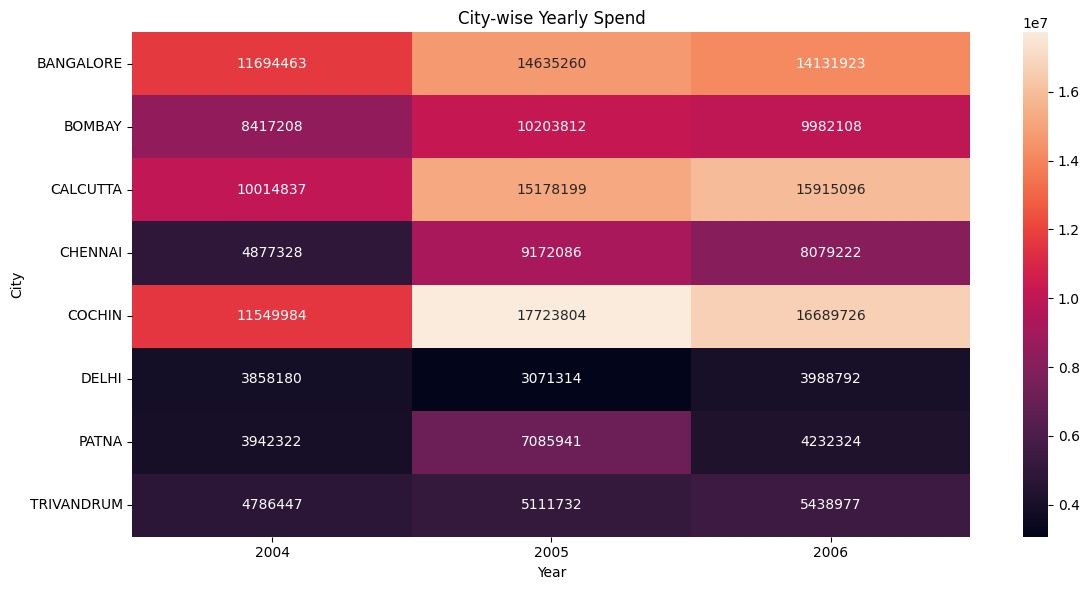

In [11]:
city_year_product = (
    spend_with_customer.assign(Year=spend_with_customer['Month'].dt.year)
    .groupby(['City', 'Year', 'Type'])['Amount_Clean']
    .sum()
    .reset_index()
)

display(city_year_product.head(20))

# Heatmap for one compact graphical representation:
city_year_total = (
    spend_with_customer.assign(Year=spend_with_customer['Month'].dt.year)
    .groupby(['City', 'Year'])['Amount_Clean']
    .sum()
    .unstack(fill_value=0)
)

plt.figure(figsize=(12, 6))
sns.heatmap(city_year_total, annot=True, fmt='.0f')
plt.title('City-wise Yearly Spend')
plt.xlabel('Year')
plt.ylabel('City')
plt.tight_layout()
plt.show()


## 12. Monthly comparison of total spend, city-wise

Requirement: compare total monthly spend across cities. fileciteturn0file0L80-L81

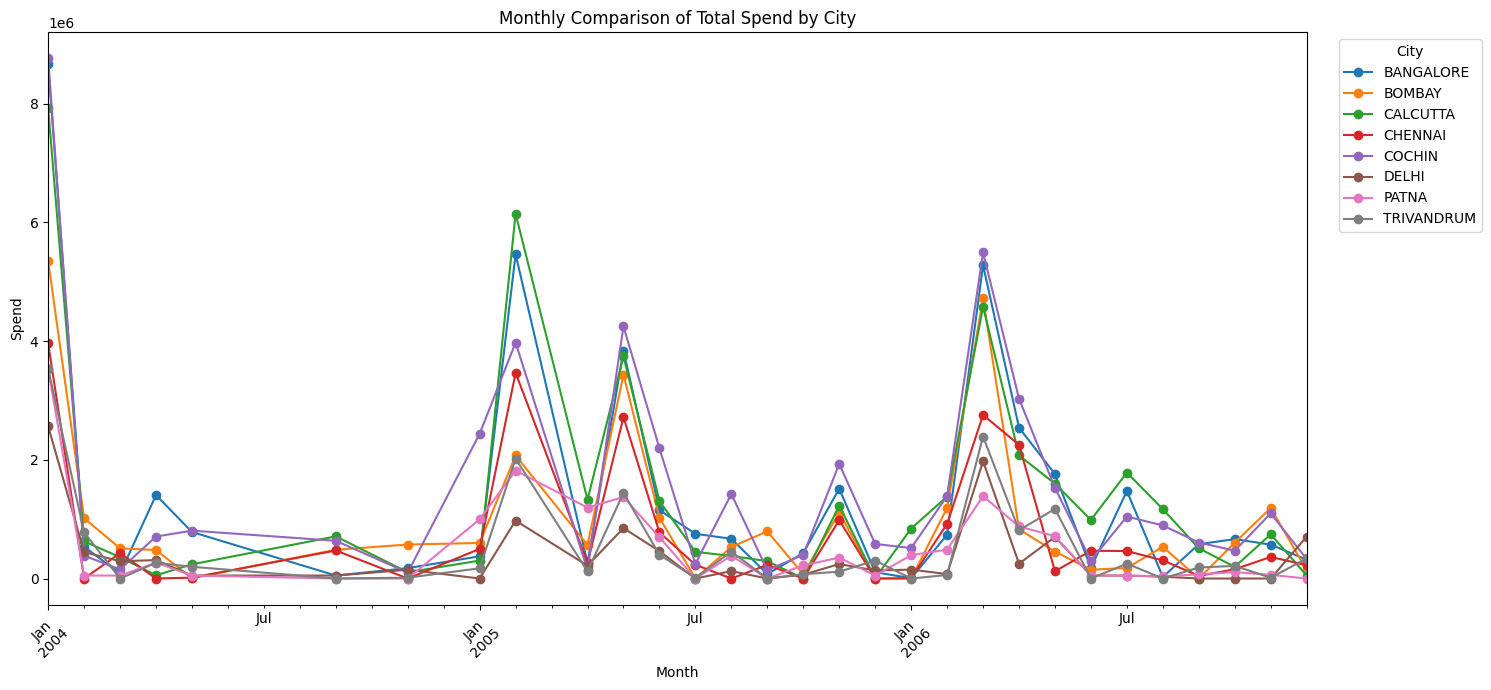

In [12]:
monthly_city_spend = (
    spend_with_customer.groupby(['Period', 'City'])['Amount_Clean']
    .sum()
    .unstack(fill_value=0)
)

plt.figure(figsize=(15, 7))
monthly_city_spend.plot(ax=plt.gca(), marker='o')
plt.title('Monthly Comparison of Total Spend by City')
plt.xlabel('Month')
plt.ylabel('Spend')
plt.legend(title='City', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 13. Yearly spend on air tickets

The case study specifically asks for a comparison of yearly spend on air tickets. fileciteturn0file0L80-L83

,Air Ticket Spend
Year,
2004,"4,357,225.35"
2005,"10,550,152.21"
2006,"5,248,469.56"


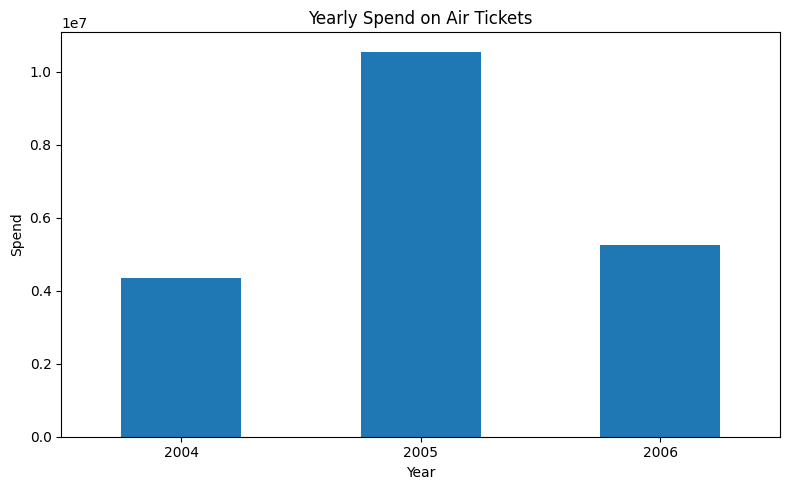

In [13]:
air_ticket_yearly = (
    spend_with_customer.loc[spend_with_customer['Type'] == 'AIR TICKET']
    .assign(Year=lambda x: x['Month'].dt.year)
    .groupby('Year')['Amount_Clean']
    .sum()
)

display(air_ticket_yearly.to_frame('Air Ticket Spend'))

plt.figure(figsize=(8, 5))
air_ticket_yearly.plot(kind='bar')
plt.title('Yearly Spend on Air Tickets')
plt.xlabel('Year')
plt.ylabel('Spend')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 14. Monthly spend for each product / transaction type

This view helps identify changes and possible seasonality in spending. fileciteturn0file0L80-L84

Type,AIR TICKET,AUTO,BIKE,BUS TICKET,CAMERA,CAR,CLOTHES,FOOD,JEWELLERY,MOVIE TICKET,PETRO,RENTAL,SANDALS,SHOPPING,TRAIN TICKET
Period,,,,,,,,,,,,,,,
2004-01,"3,053,884.61","254,745.28","376,633.28","3,563,648.59","8,546,992.33","1,808,285.79","2,370,537.40","5,928,981.00","1,904,642.18","1,538,392.99","4,246,095.43","2,607,584.26","937,690.61","4,937,924.11","2,203,774.10"
2004-02,"658,572.90",0.00,"50,001.00","981,696.51",0.00,0.00,"264,892.01","300,031.83","343,726.40",0.00,"853,541.78",0.00,0.00,"383,489.41",0.00
2004-03,"5,000.50",0.00,0.00,0.00,"1,092,224.18",0.00,"50,000.50","50,000.00","50,000.00",0.00,"462,931.43",0.00,"47,866.78",0.00,"113,889.88"
2004-04,0.00,0.00,0.00,"549,087.95","483,603.21",0.00,0.00,"363,548.29","141,769.02","50,000.00","90,197.61",0.00,0.00,"1,454,690.26","356,519.00"
2004-05,0.00,0.00,0.00,"361,141.31",0.00,0.00,0.00,"353,619.48","139,648.20",0.00,0.00,"986,717.34","50,001.50",0.00,"255,449.53"


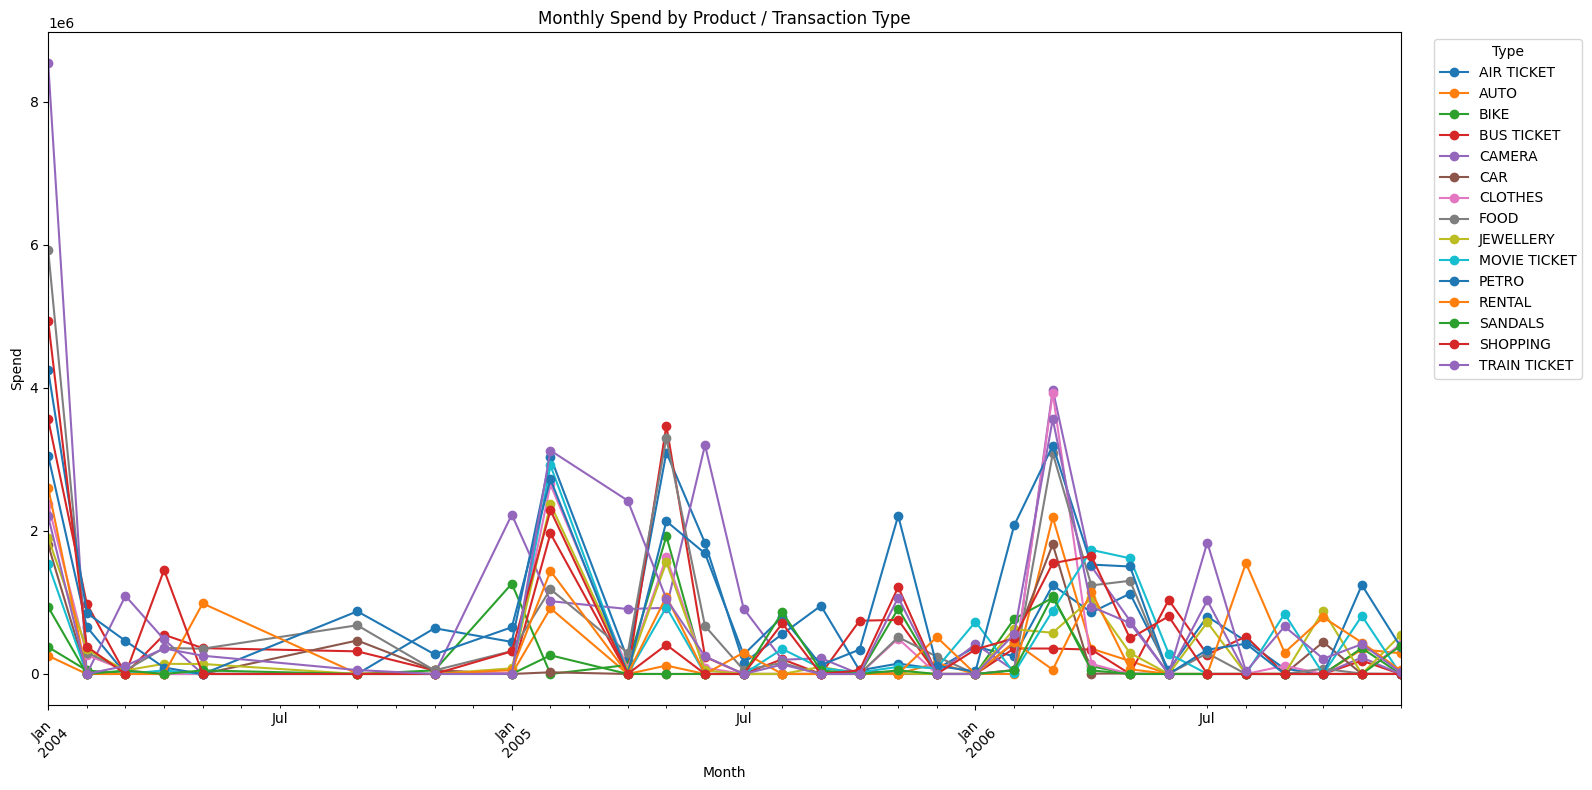

In [14]:
monthly_product_spend = (
    spend_with_customer.groupby(['Period', 'Type'])['Amount_Clean']
    .sum()
    .unstack(fill_value=0)
)

display(monthly_product_spend.head())

plt.figure(figsize=(16, 8))
monthly_product_spend.plot(ax=plt.gca(), marker='o')
plt.title('Monthly Spend by Product / Transaction Type')
plt.xlabel('Month')
plt.ylabel('Spend')
plt.legend(title='Type', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


## 15. User-defined function: Top 10 repayment customers by city

The function below accepts:
- `product`: Gold / Silver / Platinum
- `time_period`: yearly / monthly

It automatically identifies the top 10 customers **within each city** by repayment amount for the selected product and time period. This directly addresses the final case-study requirement. fileciteturn0file0L85-L89

In [15]:
# Attach customer attributes to repayment data
repayment_analysis = repayment_clean.merge(
    customer_clean[['Customer', 'City', 'Product']],
    on='Customer',
    how='left'
)

def top_10_repayment_customers(product, time_period='yearly'):
    '''
    Return the top 10 repayment customers for each city for a selected
    card product and time period.

    Parameters
    ----------
    product : str
        Gold, Silver or Platinum.
    time_period : str
        'yearly' or 'monthly'.

    Returns
    -------
    pandas.DataFrame
    '''
    product_map = {
        'gold': 'Gold',
        'silver': 'Silver',
        'platinum': 'Platinum'
    }

    period_map = {
        'yearly': 'Year',
        'monthly': 'Month'
    }

    product_key = str(product).strip().lower()
    period_key = str(time_period).strip().lower()

    if product_key not in product_map:
        raise ValueError("product must be Gold, Silver or Platinum")

    if period_key not in period_map:
        raise ValueError("time_period must be yearly or monthly")

    df = repayment_analysis[
        repayment_analysis['Product'] == product_map[product_key]
    ].copy()

    period_col = period_map[period_key]
    if period_col == 'Year':
        df['Period'] = df['Month'].dt.year
    else:
        df['Period'] = df['Month'].dt.to_period('M').astype(str)

    summary = (
        df.groupby(['City', 'Period', 'Customer'])['Amount_Clean']
        .sum()
        .reset_index(name='Total Repayment')
    )

    summary = summary.sort_values(
        ['City', 'Period', 'Total Repayment'],
        ascending=[True, True, False]
    )

    # Rank customers independently inside each City + Period
    summary['Rank'] = (
        summary.groupby(['City', 'Period'])['Total Repayment']
        .rank(method='first', ascending=False)
    )

    return (
        summary.loc[summary['Rank'] <= 10]
        .sort_values(['City', 'Period', 'Rank'])
        .reset_index(drop=True)
    )


### Example 1: Gold cards, yearly

In [16]:
gold_yearly_top10 = top_10_repayment_customers('Gold', 'yearly')
display(gold_yearly_top10.head(30))


,City,Period,Customer,Total Repayment,Rank
0,BANGALORE,2004,A14,"2,770,261.30",1.00
1,BANGALORE,2004,A1,"2,359,797.84",2.00
2,BANGALORE,2004,A13,"2,337,012.77",3.00
3,BANGALORE,2004,A43,"1,906,497.47",4.00
4,BANGALORE,2004,A30,"978,777.17",5.00
5,BANGALORE,2004,A63,"788,855.60",6.00
6,BANGALORE,2005,A43,"4,006,956.60",1.00
7,BANGALORE,2005,A13,"3,757,673.00",2.00
8,BANGALORE,2005,A30,"2,667,746.38",3.00
9,BANGALORE,2005,A14,"2,491,981.61",4.00


### Example 2: Platinum cards, monthly

In [17]:
platinum_monthly_top10 = top_10_repayment_customers('Platinum', 'monthly')
display(platinum_monthly_top10.head(30))


,City,Period,Customer,Total Repayment,Rank
0,BANGALORE,2004-01,A37,"500,008.58",1.00
1,BANGALORE,2004-01,A52,"263,853.18",2.00
2,BANGALORE,2004-01,A5,"60,012.00",3.00
3,BANGALORE,2004-01,A19,"40,000.00",4.00
4,BANGALORE,2004-05,A37,"144,582.08",1.00
5,BANGALORE,2004-05,A5,"8,797.07",2.00
6,BANGALORE,2004-09,A37,"25,958.96",1.00
7,BANGALORE,2004-09,A19,"10,000.00",2.00
8,BANGALORE,2004-11,A37,"100,003.00",1.00
9,BANGALORE,2005-01,A19,"10,000.00",1.00


## 16. Final business summary

The following values are generated directly from the cleaned data and can be used as the executive summary of the analysis.

In [18]:
summary = pd.DataFrame({
    'Metric': [
        'Distinct customers',
        'Distinct transaction categories',
        'Average monthly spend per customer',
        'Average monthly repayment per customer',
        'Total bank interest at 2.9%',
        'City with maximum spend',
        'Highest-spending age group'
    ],
    'Result': [
        distinct_customers,
        distinct_categories,
        f'₹{avg_monthly_spend:,.2f}',
        f'₹{avg_monthly_repayment:,.2f}',
        f'₹{monthly_financials["Bank Interest"].sum():,.2f}',
        city_spend.idxmax(),
        age_group_spend.idxmax()
    ]
})

display(summary)

print('Top 5 transaction types:')
display(top_5_products)

print('Top 10 customers by repayment:')
display(top_10_customers_repayment)


,Metric,Result
0,Distinct customers,100
1,Distinct transaction categories,15
2,Average monthly spend per customer,"₹272,343.35"
3,Average monthly repayment per customer,"₹306,995.44"
4,Total bank interest at 2.9%,"₹998,733.65"
5,City with maximum spend,COCHIN
6,Highest-spending age group,41-50


Top 5 transaction types:


,Type,Amount_Clean
0,PETRO,"28,597,384.98"
1,CAMERA,"27,690,738.44"
2,FOOD,"20,519,243.60"
3,AIR TICKET,"20,155,847.12"
4,TRAIN TICKET,"19,995,825.72"


Top 10 customers by repayment:


,Customer,Total Repayment
0,A61,"10,539,142.91"
1,A60,"9,876,290.74"
2,A13,"9,572,000.66"
3,A43,"8,489,871.46"
4,A45,"8,448,334.87"
5,A12,"8,334,760.16"
6,A14,"7,943,268.63"
7,A44,"7,744,730.12"
8,A39,"7,622,483.30"
9,A42,"7,615,460.86"


### Key interpretation notes

- Spend and repayment were capped according to the case-study rules before analysis.
- Interest was calculated only for months where repayment exceeded spend.
- The age-group result depends on the explicitly defined age bands above because the source case study does not specify age-band boundaries.
- `Platimum` in the supplied customer data was standardized to `Platinum` so the requested function can accept the case-study spelling.
- All monetary calculations use the cleaned transaction amounts.
